# Dataset overview

Understand how experiments work and how data is organized

Identify available data

Explore data size, distributions, missing values…

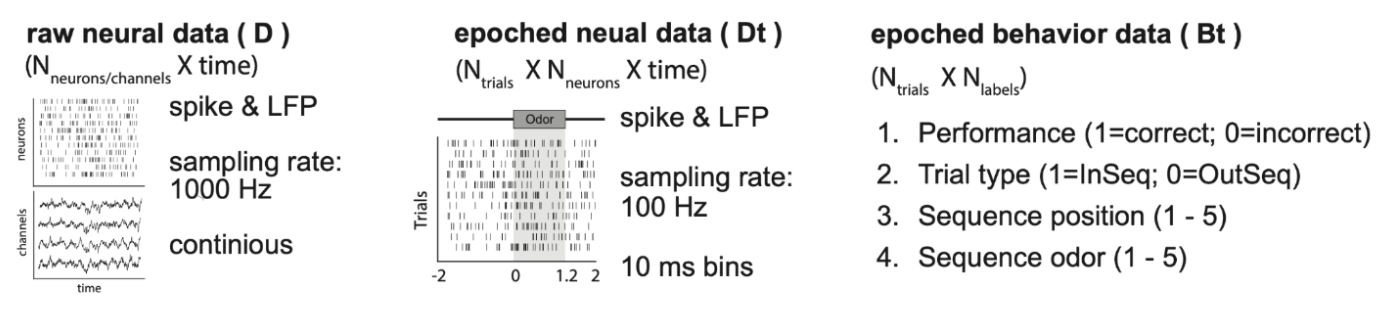

**Raw dataset**

- 5 rats: Barat, Buchanan, Superchris, Stella, Mitt
- files for each rat:
    - bvr -- behavior
    - lfp -- LFP (local field potentials)
    - spk -- spike
    - wfm -- ignore for this project

**Epoched data** 

- 5 rats: Barat, Buchanan, Superchris, Stella, Mitt
- files for each rat:
    - bvr -- behavior
    - lfp -- LFP (local field potentials)
    - spk -- spike

## LFP EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
import os

os.chdir(r"C:\Users\new account\Desktop\UCI Fall 2026\hippocampal-representation-learning")

In [32]:
# Load the .npz file --- rat = Mitt
raw_mitt_lfp = np.load('data/raw_data/080718_mitt/080718_mitt_lfp.npz')

# List all the variable/array names stored inside the file
print("Available keys:", raw_mitt_lfp.files)

# Access a specific array using its key
raw_mitt_lfp_keys= raw_mitt_lfp['keys']
print(raw_mitt_lfp_keys)

raw_mitt_lfp_data = raw_mitt_lfp['data']
print(raw_mitt_lfp_data)

Available keys: ['keys', 'data']
['T1_LFP_Raw' 'T2_LFP_Raw' 'T3_LFP_Raw' 'T4_LFP_Raw' 'T5_LFP_Raw'
 'T6_LFP_Raw' 'T7_LFP_Raw' 'T8_LFP_Raw' 'T9_LFP_Raw' 'T10_LFP_Raw'
 'T12_LFP_Raw' 'T13_LFP_Raw' 'T14_LFP_Raw' 'T15_LFP_Raw' 'T16_LFP_Raw'
 'T17_LFP_Raw' 'T18_LFP_Raw' 'T19_LFP_Raw' 'T20_LFP_Raw' 'T21_LFP_Raw'
 'T22_LFP_Raw' 'T23_LFP_Raw']
[[-0.13305664 -0.16235352 -0.19287109 ...  0.09765625  0.11108398
   0.1184082 ]
 [-0.1574707  -0.17700195 -0.234375   ...  0.15380859  0.14038086
   0.13793945]
 [-0.0402832  -0.08178711 -0.11962891 ...  0.12451172  0.10742188
   0.08544922]
 ...
 [ 0.16601562  0.10742188  0.0793457  ...  0.11230469  0.1159668
   0.12084961]
 [ 0.03662109 -0.01464844 -0.0378418  ...  0.09887695  0.1184082
   0.12451172]
 [ 0.37231445  0.38818359  0.45043945 ... -0.01953125 -0.02319336
  -0.02197266]]


In [33]:
# Print the dimensions of every array
for key in raw_mitt_lfp.files:
    array = raw_mitt_lfp[key]
    print(f"Array: {key}")
    print(f"  Shape: {array.shape}")
    print(f"  Number of dimensions: {array.ndim}")
    print(f"  Data type: {array.dtype}")
    print()

Array: keys
  Shape: (22,)
  Number of dimensions: 1
  Data type: <U11

Array: data
  Shape: (22, 5255152)
  Number of dimensions: 2
  Data type: float64



The raw LFP data has 22 channels (T1 - T23, no T11), each with 5,255,152 data points (time points).

### missingness

In [34]:
channel_names = raw_mitt_lfp_keys
lfp_data = raw_mitt_lfp_data

# Count missing values (NaNs) in each channel
missing_counts = np.isnan(lfp_data).sum(axis=1)

# Calculate percentage of missing values per channel
missing_percentages = np.isnan(lfp_data).mean(axis=1) * 100

missingness = pd.DataFrame({
    'Channel': channel_names,
    'Total_samples': lfp_data.shape[1],
    'Missing_samples': missing_counts,
    'Missing_percentage': missing_percentages
})

print(missingness.to_string(index=False))

    Channel  Total_samples  Missing_samples  Missing_percentage
 T1_LFP_Raw        5255152                0                 0.0
 T2_LFP_Raw        5255152                0                 0.0
 T3_LFP_Raw        5255152                0                 0.0
 T4_LFP_Raw        5255152                0                 0.0
 T5_LFP_Raw        5255152                0                 0.0
 T6_LFP_Raw        5255152                0                 0.0
 T7_LFP_Raw        5255152                0                 0.0
 T8_LFP_Raw        5255152                0                 0.0
 T9_LFP_Raw        5255152                0                 0.0
T10_LFP_Raw        5255152                0                 0.0
T12_LFP_Raw        5255152                0                 0.0
T13_LFP_Raw        5255152                0                 0.0
T14_LFP_Raw        5255152                0                 0.0
T15_LFP_Raw        5255152                0                 0.0
T16_LFP_Raw        5255152              

### number summary

In [35]:
# Calculate summary statistics for each channel
summary = []

for name, channel in zip(channel_names, lfp_data):
    # Exclude NaN and infinite values
    valid = channel[np.isfinite(channel)]

    summary.append({
        'Channel': name,
        'N_valid': len(valid),
        'Min': np.min(valid) if len(valid) else np.nan,
        'Q1': np.percentile(valid, 25) if len(valid) else np.nan,
        'Median': np.median(valid) if len(valid) else np.nan,
        'Mean': np.mean(valid) if len(valid) else np.nan,
        'Q3': np.percentile(valid, 75) if len(valid) else np.nan,
        'Max': np.max(valid) if len(valid) else np.nan,
        'SD': np.std(valid) if len(valid) else np.nan
    })

summary_df = pd.DataFrame(summary)

print(summary_df.round(4).to_string(index=False))

    Channel  N_valid     Min      Q1  Median    Mean     Q3    Max     SD
 T1_LFP_Raw  5255152 -2.0801 -0.1123 -0.0061  0.0011 0.1074 1.0229 0.1599
 T2_LFP_Raw  5255152 -1.5710 -0.1331 -0.0110  0.0025 0.1294 1.2708 0.1983
 T3_LFP_Raw  5255152 -1.1853 -0.1123 -0.0134  0.0011 0.1025 0.8069 0.1593
 T4_LFP_Raw  5255152 -2.5000 -0.1123 -0.0134  0.0015 0.1038 0.8752 0.1603
 T5_LFP_Raw  5255152 -1.1267 -0.1062 -0.0134  0.0004 0.0964 0.9351 0.1485
 T6_LFP_Raw  5255152 -1.9568 -0.1221 -0.0110  0.0023 0.1147 1.7920 0.1778
 T7_LFP_Raw  5255152 -1.7725 -0.1123 -0.0085  0.0018 0.1099 1.2915 0.1641
 T8_LFP_Raw  5255152 -1.1108 -0.1074 -0.0122  0.0014 0.0989 0.8801 0.1508
 T9_LFP_Raw  5255152 -1.3611 -0.1196 -0.0073  0.0015 0.1172 1.0449 0.1785
T10_LFP_Raw  5255152 -2.1033 -0.1367 -0.0061  0.0013 0.1343 1.4722 0.2124
T12_LFP_Raw  5255152 -0.9668 -0.0928 -0.0012  0.0019 0.0952 0.8142 0.1338
T13_LFP_Raw  5255152 -1.0791 -0.1123 -0.0024  0.0021 0.1111 0.9912 0.1676
T14_LFP_Raw  5255152 -0.8960 -0.1294  

### plot the first 1000 time points

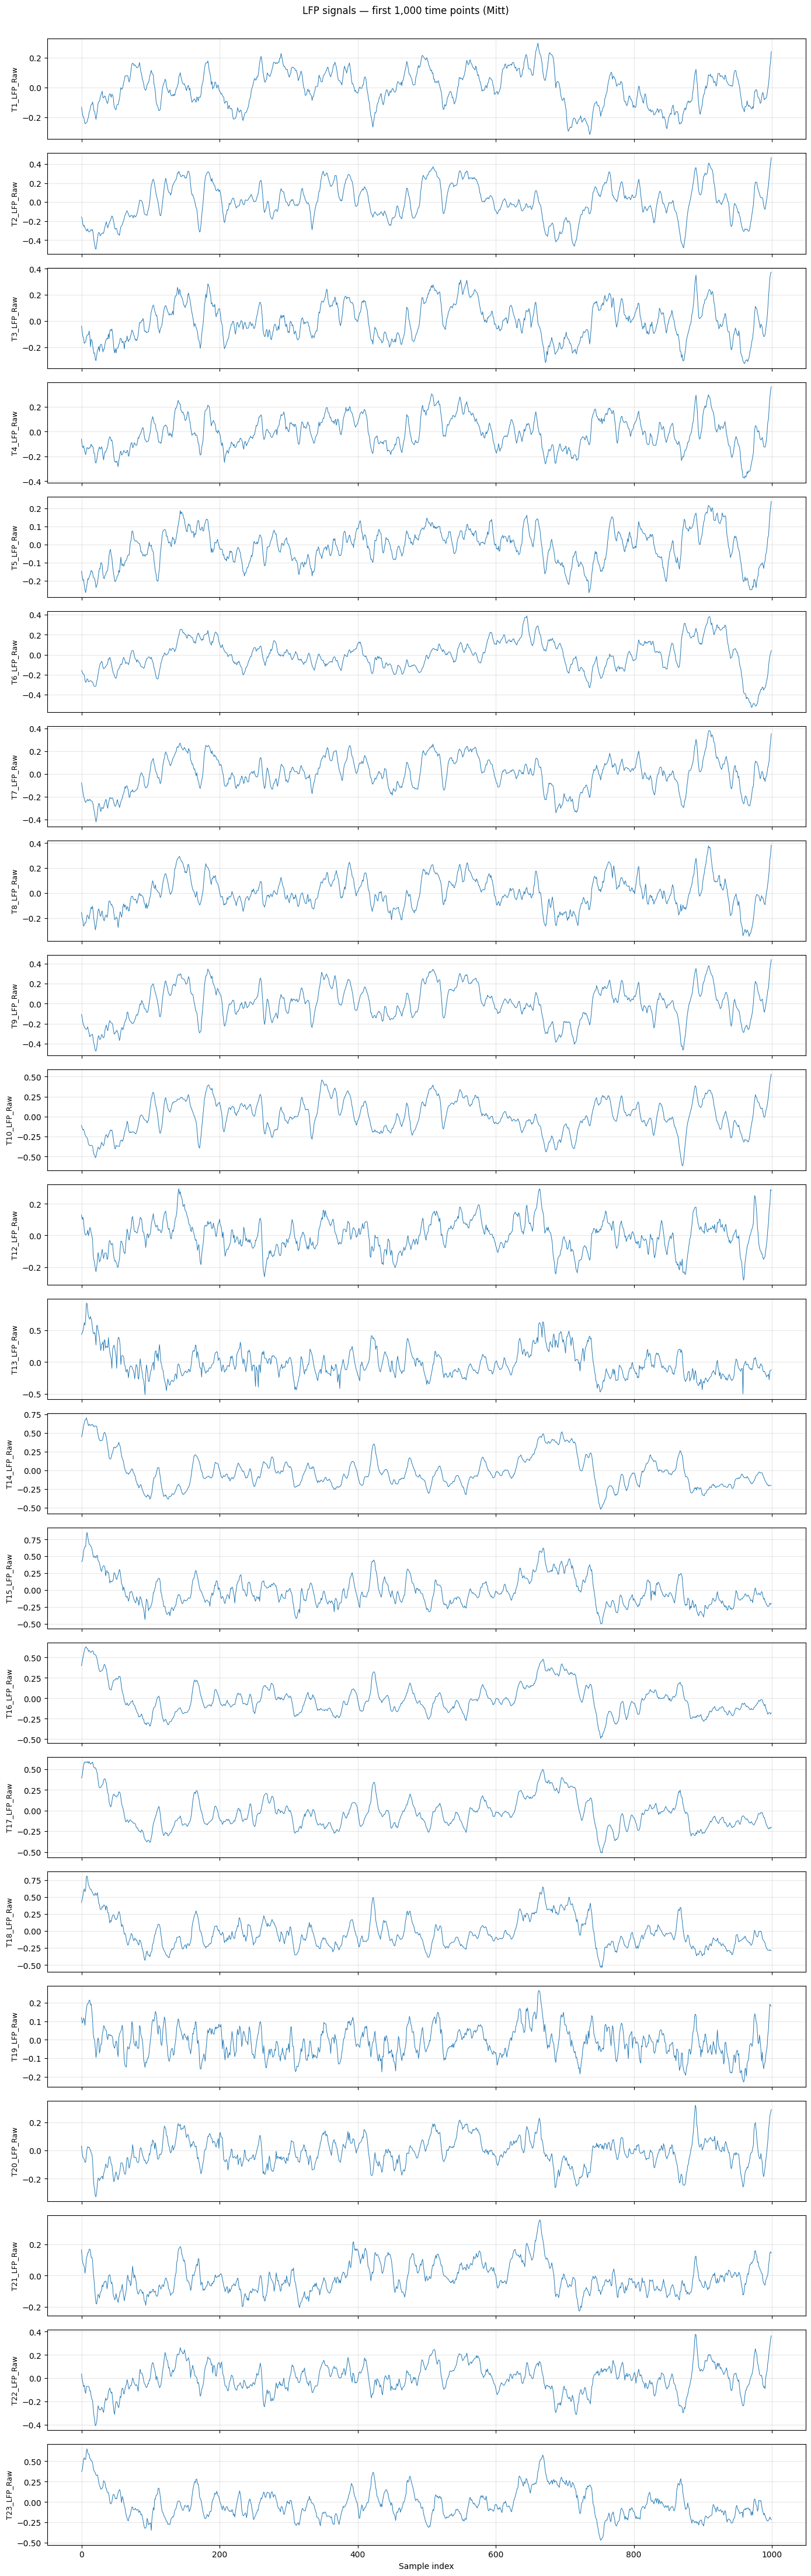

In [36]:
n_channels = len(channel_names)
n_samples = 1000  # Number of time points to plot

fig, axes = plt.subplots(
    n_channels, 1,
    figsize=(14, 2 * n_channels),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(np.arange(n_samples), lfp_data[i, :n_samples],
            linewidth=0.7)
    ax.set_ylabel(channel_names[i], fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Sample index")
fig.suptitle("LFP signals — first 1,000 time points (Mitt)", y=1.002)
plt.tight_layout()
plt.show()

## Behavior EDA

In [12]:
# Load the .npz file --- rat = Mitt
raw_mitt_bvr = np.load('data/raw_data/080718_mitt/080718_mitt_bvr.npz')

# List all the variable/array names stored inside the file
print("Available keys:", raw_mitt_bvr.files)

# Access a specific array using its key
raw_mitt_bvr_data= raw_mitt_bvr['data']
print(raw_mitt_bvr_data)

raw_mitt_bvr_keys = raw_mitt_bvr['keys']
print(raw_mitt_bvr_keys)

Available keys: ['data', 'keys']
[[1.05750000e-02 1.15750000e-02 1.25750000e-02 ... 7.35963257e+03
  7.35963357e+03 7.35963458e+03]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]
['TimeBin' 'Odor1' 'Odor2' 'Odor3' 'Odor4' 'Odor5' 'Position1' 'Position2'
 'Position3' 'Position4' 'Position5' 'InSeqLog' 'PerformanceLog'
 'PokeEvents' 'FrontReward' 'BackReward' 'XvalRatMazePosition'
 'YvalRatMazePosition']


In [13]:
# Print the dimensions of every array
for key in raw_mitt_bvr.files:
    array = raw_mitt_bvr[key]
    print(f"Array: {key}")
    print(f"  Shape: {array.shape}")
    print(f"  Number of dimensions: {array.ndim}")
    print(f"  Data type: {array.dtype}")
    print()

Array: data
  Shape: (18, 5255152)
  Number of dimensions: 2
  Data type: float64

Array: keys
  Shape: (18,)
  Number of dimensions: 1
  Data type: <U19



The raw behavior data has 18 labels, each with 5,255,152 data points (time points).

### missingness

In [30]:
label_names = raw_mitt_bvr_keys
bvr_data = raw_mitt_bvr_data

# Count missing values (NaNs) in each label
missing_counts = np.isnan(bvr_data).sum(axis=1)

# Calculate percentage of missing values per label
missing_percentages = np.isnan(bvr_data).mean(axis=1) * 100

missingness = pd.DataFrame({
    'Label': label_names,
    'Total_samples': bvr_data.shape[1],
    'Missing_samples': missing_counts,
    'Missing_percentage': missing_percentages
})

print(missingness.to_string(index=False))

              Label  Total_samples  Missing_samples  Missing_percentage
            TimeBin        5255152                0                 0.0
              Odor1        5255152                0                 0.0
              Odor2        5255152                0                 0.0
              Odor3        5255152                0                 0.0
              Odor4        5255152                0                 0.0
              Odor5        5255152                0                 0.0
          Position1        5255152                0                 0.0
          Position2        5255152                0                 0.0
          Position3        5255152                0                 0.0
          Position4        5255152                0                 0.0
          Position5        5255152                0                 0.0
           InSeqLog        5255152                0                 0.0
     PerformanceLog        5255152                0             

### number summary

In [17]:
# Calculate summary statistics for selected channels
selected_labels = ['TimeBin', 'XvalRatMazePosition', 'YvalRatMazePosition']
summary = []

for name, label in zip(raw_mitt_bvr_keys, raw_mitt_bvr_data):
    if name not in selected_labels:
        continue

    # Exclude NaN and infinite values
    valid = label[np.isfinite(label)]

    summary.append({
        'Label': name,
        'N_valid': len(valid),
        'Min': np.min(valid) if len(valid) else np.nan,
        'Q1': np.percentile(valid, 25) if len(valid) else np.nan,
        'Median': np.median(valid) if len(valid) else np.nan,
        'Mean': np.mean(valid) if len(valid) else np.nan,
        'Q3': np.percentile(valid, 75) if len(valid) else np.nan,
        'Max': np.max(valid) if len(valid) else np.nan,
        'SD': np.std(valid) if len(valid) else np.nan
    })

summary_df = pd.DataFrame(summary)

print(summary_df.round(4).to_string(index=False))

              Label  N_valid    Min        Q1    Median      Mean        Q3       Max        SD
            TimeBin  5255152 0.0106 1497.2093 2810.9971 3308.9451 6045.8468 7359.6346 2301.1319
XvalRatMazePosition  5255152 0.0000    0.0000    0.0000   12.4143    0.0000 1019.0000   98.7454
YvalRatMazePosition  5255152 0.0000    0.0000    0.0000    7.5772    0.0000  665.0000   47.6154


In [18]:
# Unique values and value counts for the other labels
excluded_labels = ['TimeBin', 'XvalRatMazePosition', 'YvalRatMazePosition']
summary = []

for name, label in zip(raw_mitt_bvr_keys, raw_mitt_bvr_data):
    if name in excluded_labels:
        continue

    # Exclude NaN and infinite values
    valid = label[np.isfinite(label)]

    unique_values, counts = np.unique(valid, return_counts=True)

    summary.append({
        'Label': name,
        'N_valid': len(valid),
        'N_unique': len(unique_values),
        'Value_counts': dict(zip(unique_values, counts))
    })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

         Label  N_valid  N_unique                        Value_counts
         Odor1  5255152         2             {0.0: 5255069, 1.0: 83}
         Odor2  5255152         2             {0.0: 5255087, 1.0: 65}
         Odor3  5255152         2             {0.0: 5255092, 1.0: 60}
         Odor4  5255152         2             {0.0: 5255108, 1.0: 44}
         Odor5  5255152         2             {0.0: 5255112, 1.0: 40}
     Position1  5255152         2             {0.0: 5255073, 1.0: 79}
     Position2  5255152         2             {0.0: 5255089, 1.0: 63}
     Position3  5255152         2             {0.0: 5255094, 1.0: 58}
     Position4  5255152         2             {0.0: 5255101, 1.0: 51}
     Position5  5255152         2             {0.0: 5255111, 1.0: 41}
      InSeqLog  5255152         3  {-1.0: 30, 0.0: 5254860, 1.0: 262}
PerformanceLog  5255152         3  {-1.0: 46, 0.0: 5254860, 1.0: 246}
    PokeEvents  5255152         3 {-1.0: 292, 0.0: 5254568, 1.0: 292}
   FrontReward  5255

### plot

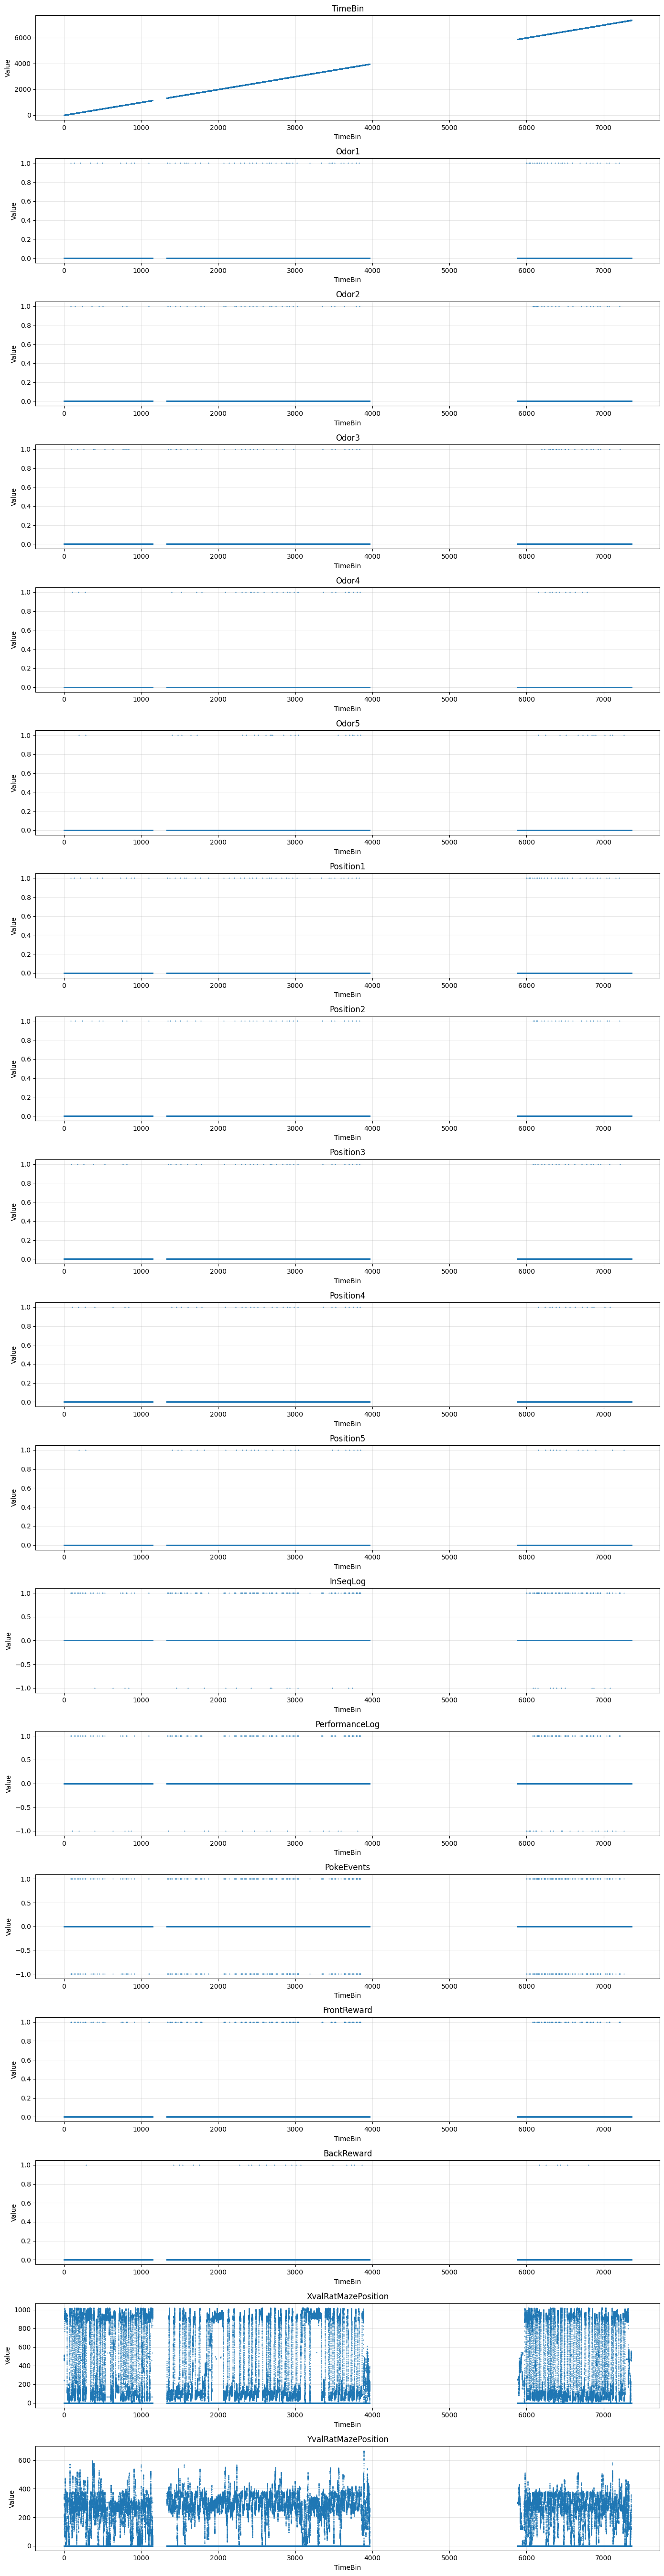

In [27]:
# Get TimeBin
time_idx = np.where(raw_mitt_bvr_keys == 'TimeBin')[0][0]
time = np.asarray(
    raw_mitt_bvr_data[time_idx], dtype=float
).ravel()

# Plot all labels
n_labels = len(raw_mitt_bvr_keys)
fig, axes = plt.subplots(
    n_labels, 1,
    figsize=(14, max(3 * n_labels, 10)),
    sharex=False,
    sharey=False,
    squeeze=False
)

axes = axes.ravel()

for ax, name, label in zip(
    axes, raw_mitt_bvr_keys, raw_mitt_bvr_data
):
    values = np.asarray(label, dtype=float).ravel()

    # Match the lengths of time and channel
    n = min(len(time), len(values))
    t = time[:n]
    v = values[:n]

    # Plot all paired samples
    ax.plot(t, v, '.', markersize=1)

    ax.set_title(str(name))
    ax.set_xlabel('TimeBin')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Labels:**

- TimeBin: time in seconds??
    - There appears to be two gaps in time
- Odors: 5 sequence odors (values = 0 or 1)
- Position: 5 sequence positions (values = 0 or 1)
- InSeqLog (values = -1, 0, or 1)
- PerformanceLog (values = -1, 0, or 1)
- PokeEvents (values = -1, 0, or 1)
- FrontReward (values = 0 or 1)
- BackReward (values = 0 or 1)
- XvalRatMazePosition: continuous with gaps
- YvalRatMazePosition: continuous with gaps

What do the values represent?